# Part I: modeling the housing price

# Prepping the Data

In [2]:
import pandas as pd
import numpy as np 
from scipy import stats
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
import scipy.stats as stats
import tensorflow as tf
import copy

In [3]:
calories = {"Day 1": 1750, "Day 2": 2100, "Day 3": 3000}

series = pd.Series(calories) 

print(series[series >= 2000]) 



Day 2    2100
Day 3    3000
dtype: int64


In [4]:
df = pd.read_csv("data_CASE_group_18.csv")

print (df)

         Price  Area  No. of Bedrooms  Resale  MaintenanceStaff  Gymnasium  \
0      4150000  1475                3       0                 0          0   
1      3200000  1050                2       0                 0          0   
2     12500000  1945                3       1                 1          1   
3      4641000  1105                2       0                 0          1   
4      5000000  2585                3       0                 9          9   
...        ...   ...              ...     ...               ...        ...   
2462   5500000  1260                2       0                 0          0   
2463   8500000  1525                3       0                 0          0   
2464   9300000  1500                3       1                 1          1   
2465  13400000  2075                3       0                 0          0   
2466   4700000   950                2       0                 0          0   

      SwimmingPool  LandscapedGardens  JoggingTrack  RainWaterH

In [5]:
stats = df.describe() 

print(stats)

              Price         Area  No. of Bedrooms       Resale  \
count  2.467000e+03  2467.000000      2467.000000  2467.000000   
mean   9.803732e+06  1643.473044         2.625861     0.226996   
std    8.680468e+06   730.814725         0.679819     0.418975   
min    2.000000e+06   500.000000         1.000000     0.000000   
25%    4.760000e+06  1163.000000         2.000000     0.000000   
50%    7.800000e+06  1500.000000         3.000000     0.000000   
75%    1.090000e+07  1830.000000         3.000000     0.000000   
max    1.650000e+08  8500.000000         8.000000     1.000000   

       MaintenanceStaff    Gymnasium  SwimmingPool  LandscapedGardens  \
count       2467.000000  2467.000000   2467.000000        2467.000000   
mean           0.419133     0.746251      0.715444           0.624645   
std            1.641985     1.625421      1.629792           1.639242   
min            0.000000     0.000000      0.000000           0.000000   
25%            0.000000     0.000000    

Observe that some of the binary data has 9 as the max value

In [6]:
# Doing a quick check to make sure the data only contains 0,1,9 

df['MaintenanceStaff'].unique()

# We can infer that the 9 in this instance is missing data 

array([0, 1, 9])

In [7]:
# Doing a conversion of the data so all the 9 become missing values 

cols = df.columns[4:39]
df[cols] = df[cols].astype(float).replace(9, np.nan)
df.iloc[:, 4:39] = df.iloc[:, 4:39].replace(9, np.nan)

#And a double check to make sure all the 9s are now missing values 
print(df.iloc[:, 4:39].isin([9]).sum().sum())  
print(df.iloc[:, 4:39].isna().sum())



0
MaintenanceStaff       84
Gymnasium              84
SwimmingPool           84
LandscapedGardens      84
JoggingTrack           84
RainWaterHarvesting    84
IndoorGames            84
ShoppingMall           84
Intercom               84
SportsFacility         84
ATM                    84
ClubHouse              84
School                 84
24X7Security           84
PowerBackup            84
CarParking             84
StaffQuarter           84
Cafeteria              84
MultipurposeRoom       84
Hospital               84
WashingMachine         84
Gasconnection          84
AC                     84
Wifi                   84
Children'splayarea     84
LiftAvailable          84
BED                    84
VaastuCompliant        84
Microwave              84
GolfCourse             84
TV                     84
DiningTable            84
Sofa                   84
Wardrobe               84
Refrigerator           84
dtype: int64


In [8]:
# We see that all the binary variables have the same amount of missing variable, so we check that the same rows are missing every column 

is_missing = df[cols].isna()
missing_per_row = is_missing.sum(axis=1)
print(missing_per_row.value_counts().sort_index())



0     2383
35      84
Name: count, dtype: int64


In [9]:
is_missing.all(axis=1).sum()   # rows missing in every column
is_missing.any(axis=1).sum()   # rows missing in at least one column

np.int64(84)

In [10]:
# Ok We confirmed that the missing data is pretty much all or nothing, before dropping this data it is important to check if the data is statistically different

df['all_missing'] = df[cols].isna().all(axis=1)

vars_ = ['Price', 'Area', 'No. of Bedrooms']

comparison = df.groupby('all_missing')[vars_].mean().T
comparison.columns = ['Complete', 'Missing']          # False -> Complete, True -> Missing
comparison['Difference'] = comparison['Missing'] - comparison['Complete']

comparison['% Diff'] = 100 * comparison['Difference'] / comparison['Complete']

pooled_sd = df[vars_].std()
comparison['Std Diff'] = comparison['Difference'] / pooled_sd

print(comparison.round(2))




                   Complete     Missing  Difference  % Diff  Std Diff
Price            9830328.97  9049202.35  -781126.62   -7.95     -0.09
Area                1643.01     1656.73       13.72    0.84      0.02
No. of Bedrooms        2.63        2.55       -0.08   -3.08     -0.12


In [11]:
# Now there is sufficient support for dropping it 

df_clean = df.loc[~df['all_missing']].drop(columns='all_missing')

print(df_clean.head())
df_clean.describe()

      Price  Area  No. of Bedrooms  Resale  MaintenanceStaff  Gymnasium  \
0   4150000  1475                3       0               0.0        0.0   
1   3200000  1050                2       0               0.0        0.0   
2  12500000  1945                3       1               1.0        1.0   
3   4641000  1105                2       0               0.0        1.0   
5   4044000  1165                2       0               0.0        0.0   

   SwimmingPool  LandscapedGardens  JoggingTrack  RainWaterHarvesting  ...  \
0           0.0                0.0           0.0                  0.0  ...   
1           0.0                0.0           0.0                  0.0  ...   
2           1.0                1.0           1.0                  1.0  ...   
3           0.0                0.0           0.0                  0.0  ...   
5           0.0                0.0           0.0                  0.0  ...   

   LiftAvailable  BED  VaastuCompliant  Microwave  GolfCourse   TV  \
0         

,Price,Area,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,...,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator
count,2.383000e+03,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,...,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000
mean,9.830329e+06,1643.005875,2.628619,0.220730,0.116660,0.455308,0.423416,0.329417,0.267310,0.315149,...,0.697440,0.060848,0.317247,0.043642,0.030214,0.021821,0.033991,0.041964,0.042384,0.024339
std,8.755422e+06,732.223407,0.677182,0.414826,0.321082,0.498103,0.494204,0.470100,0.442648,0.464673,...,0.459463,0.239101,0.465502,0.204341,0.171212,0.146130,0.181243,0.200549,0.201505,0.154132
min,2.000000e+06,500.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.760000e+06,1165.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,7.800000e+06,1500.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.090000e+07,1821.000000,3.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.650000e+08,8500.000000,8.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


# Summary Statistics 

              Price         Area  No. of Bedrooms  ShoppingMall       School
count  2.467000e+03  2467.000000      2467.000000   2383.000000  2383.000000
mean   9.803732e+06  1643.473044         2.625861      0.067982     0.041544
std    8.680468e+06   730.814725         0.679819      0.251767     0.199587
min    2.000000e+06   500.000000         1.000000      0.000000     0.000000
25%    4.760000e+06  1163.000000         2.000000      0.000000     0.000000
50%    7.800000e+06  1500.000000         3.000000      0.000000     0.000000
75%    1.090000e+07  1830.000000         3.000000      0.000000     0.000000
max    1.650000e+08  8500.000000         8.000000      1.000000     1.000000


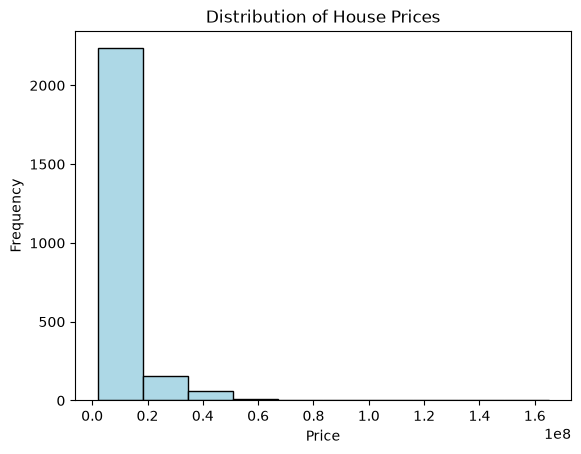

In [12]:
stats = df[['Price','Area','No. of Bedrooms','ShoppingMall','School']].describe()
print(stats)

plt.hist(df['Price'], bins=10,range=(2.000000e+06,1.650000e+08), histtype = "bar", edgecolor = "black", color = "lightblue")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")
plt.show()



In [13]:
# price = df_clean['Price'].dropna()

# # 1. Visual: histogram and Q-Q plot
# fig, ax = plt.subplots(1, 2, figsize=(11, 4))
# ax[0].hist(price, bins=50)
# ax[0].set_title('Histogram of Price')
# stats.probplot(price, dist='norm', plot=ax[1])
# ax[1].set_title('Q-Q plot')
# plt.show()

# # 2. Skewness and kurtosis (both 0 for a normal distribution, using excess kurtosis)
# print('Skew:', stats.skew(price))
# print('Excess kurtosis:', stats.kurtosis(price))

# # 3. Formal tests (null hypothesis: the data are normal)
# print(stats.shapiro(price))
# print(stats.normaltest(price))      # D'Agostino-Pearson
# print(stats.jarque_bera(price))


In [14]:
# From this we can clearly see that the data has a very long right tail 

In [15]:
cols = df_clean.columns[2:39]
random_cols = df_clean[cols].sample(n=2, axis=1, random_state=42)
print(random_cols.columns.tolist())

['CarParking', 'ClubHouse']


In [16]:
cols = ['Price', 'Area', 'CarParking', 'ClubHouse']
stats_order = ['mean', 'std', 'min', 'median', 'max']

# Summary statistics: one row per variable
s = df_clean[cols].agg(['count'] + stats_order).T

# Decimal places per variable
decimals = {'Price': 0, 'Area': 1, 'CarParking': 3, 'ClubHouse': 3}

rows = []
for v in cols:
    d = decimals[v]
    r = s.loc[v]
    cells = [f"{int(r['count']):,}"] + [f"{r[k]:,.{d}f}" for k in stats_order]
    rows.append(v + " & " + " & ".join(cells) + r" \\")
rows_tex = "\n".join(rows)

latex = r"""\begin{table}[p]
\centering
\caption{Summary Statistics}
\vspace{6pt}
\begin{tabular}{lrrrrrr}
\toprule
Variable & N & Mean & SD & Min & Median & Max \\
\midrule
%%ROWS%%
\bottomrule
\end{tabular}

\vspace{8pt}
\parbox{0.95\textwidth}{
This table reports summary statistics for the housing sample. \textit{Price} is the
listed price of the house in [currency units]. \textit{Area} is the size of the house in
[square feet]. \textit{CarParking} is an indicator variable equal to one if the house has
car parking, and zero otherwise. \textit{ClubHouse} is an indicator variable equal to one if
the house has access to a clubhouse, and zero otherwise. For indicator variables, the mean
is the fraction of houses with the feature. N is the number of observations, SD is the
standard deviation. The sample excludes 84 observations with missing data on all binary
features.}
\end{table}
""".replace("%%ROWS%%", rows_tex)

with open("table1.tex", "w") as f:
    f.write(latex)

print(latex)

\begin{table}[p]
\centering
\caption{Summary Statistics}
\vspace{6pt}
\begin{tabular}{lrrrrrr}
\toprule
Variable & N & Mean & SD & Min & Median & Max \\
\midrule
Price & 2,383 & 9,830,329 & 8,755,422 & 2,000,000 & 7,800,000 & 165,000,000 \\
Area & 2,383 & 1,643.0 & 732.2 & 500.0 & 1,500.0 & 8,500.0 \\
CarParking & 2,383 & 0.450 & 0.498 & 0.000 & 0.000 & 1.000 \\
ClubHouse & 2,383 & 0.426 & 0.495 & 0.000 & 0.000 & 1.000 \\
\bottomrule
\end{tabular}

\vspace{8pt}
\parbox{0.95\textwidth}{
This table reports summary statistics for the housing sample. \textit{Price} is the
listed price of the house in [currency units]. \textit{Area} is the size of the house in
[square feet]. \textit{CarParking} is an indicator variable equal to one if the house has
car parking, and zero otherwise. \textit{ClubHouse} is an indicator variable equal to one if
the house has access to a clubhouse, and zero otherwise. For indicator variables, the mean
is the fraction of houses with the feature. N is the number of

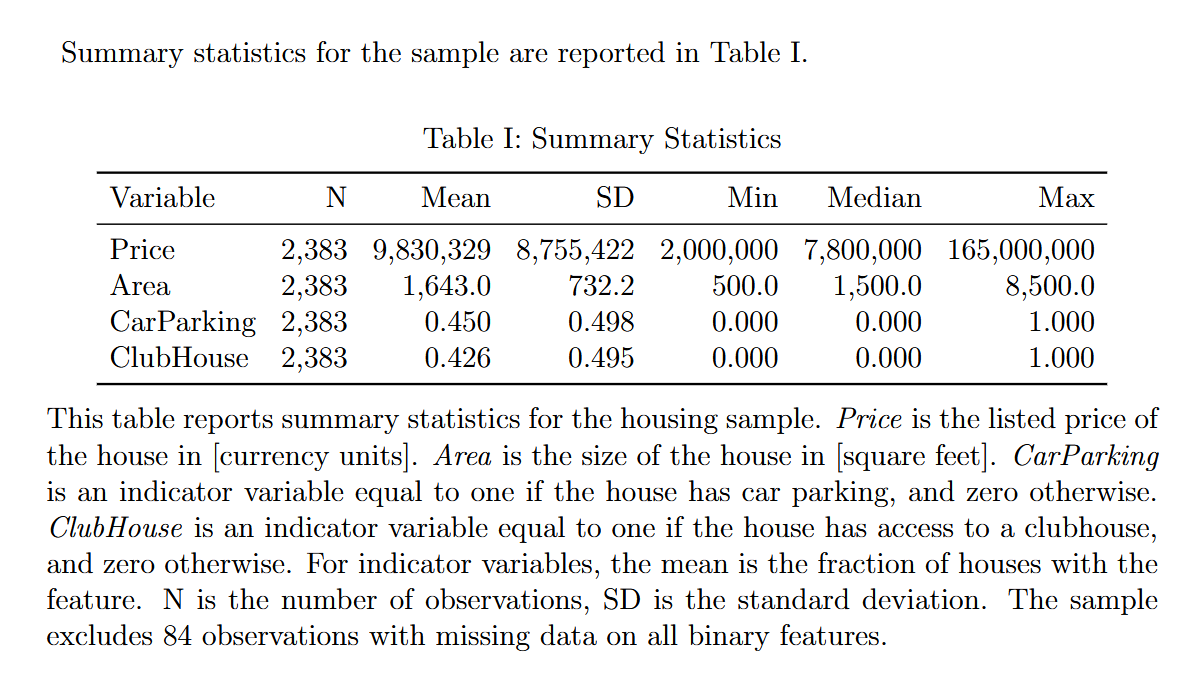

# Interpretation


The summary statistics show that the average house price is around 9.8 million, with an average area of 1.600 square units. The average value of CarParking, and ClubHouse, show that rougly half of the houses have a carpark or club house. 

In [83]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline


In [18]:
Y = df_clean['Price']
X = df_clean['Area']

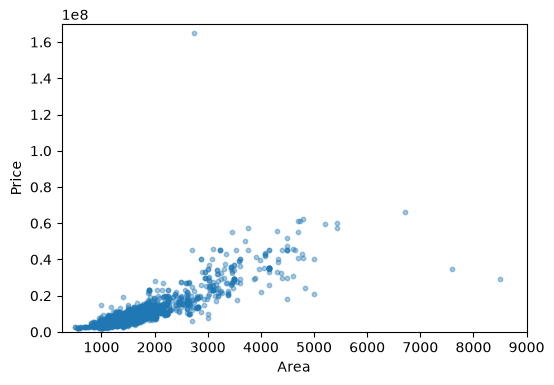

In [19]:
plt.figure(figsize=(6, 4))
plt.scatter(X, Y, alpha=0.4, s=10)
plt.xlabel("Area")
plt.ylabel("Price")
plt.axis([250, 9000, 0, 170000000])
plt.show()

In [20]:
print(df_clean.head())

      Price  Area  No. of Bedrooms  Resale  MaintenanceStaff  Gymnasium  \
0   4150000  1475                3       0               0.0        0.0   
1   3200000  1050                2       0               0.0        0.0   
2  12500000  1945                3       1               1.0        1.0   
3   4641000  1105                2       0               0.0        1.0   
5   4044000  1165                2       0               0.0        0.0   

   SwimmingPool  LandscapedGardens  JoggingTrack  RainWaterHarvesting  ...  \
0           0.0                0.0           0.0                  0.0  ...   
1           0.0                0.0           0.0                  0.0  ...   
2           1.0                1.0           1.0                  1.0  ...   
3           0.0                0.0           0.0                  0.0  ...   
5           0.0                0.0           0.0                  0.0  ...   

   LiftAvailable  BED  VaastuCompliant  Microwave  GolfCourse   TV  \
0         

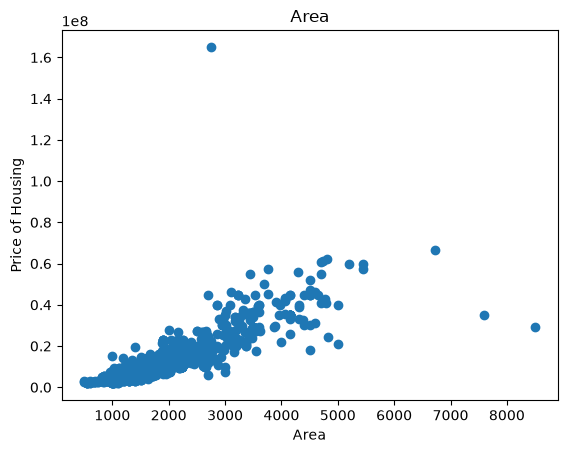

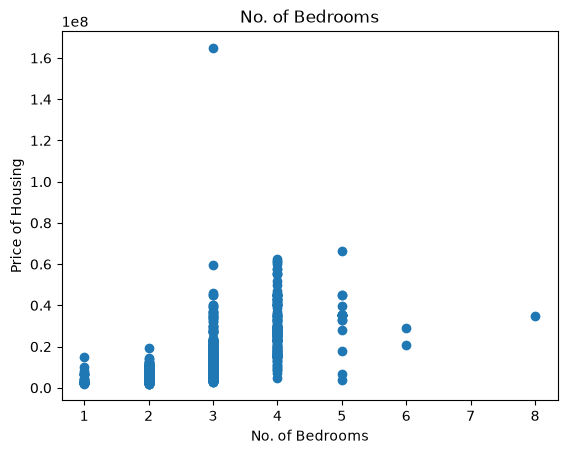

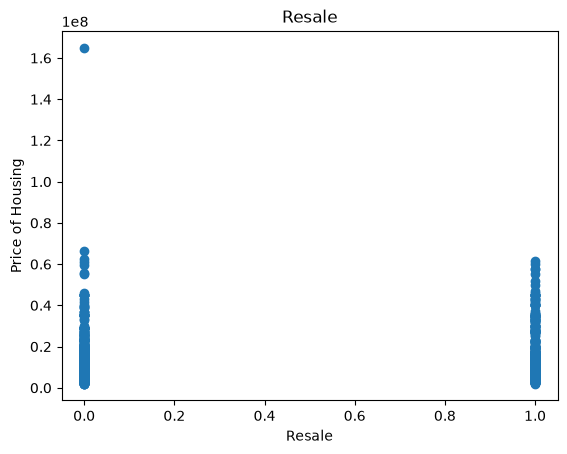

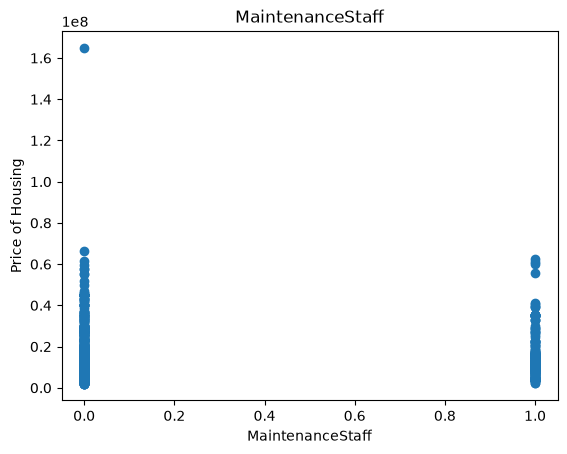

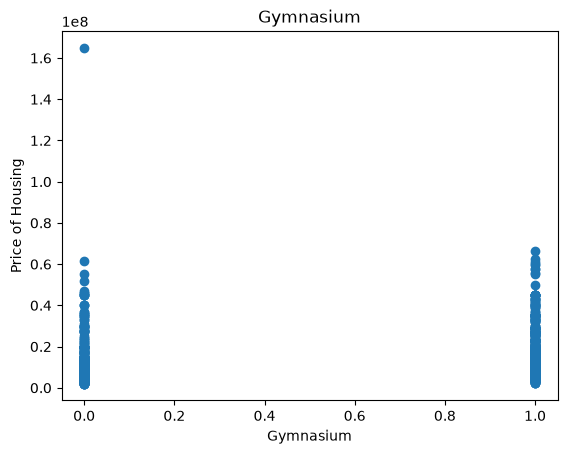

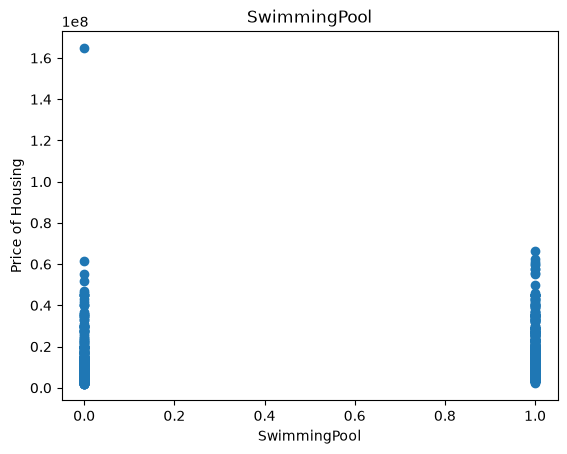

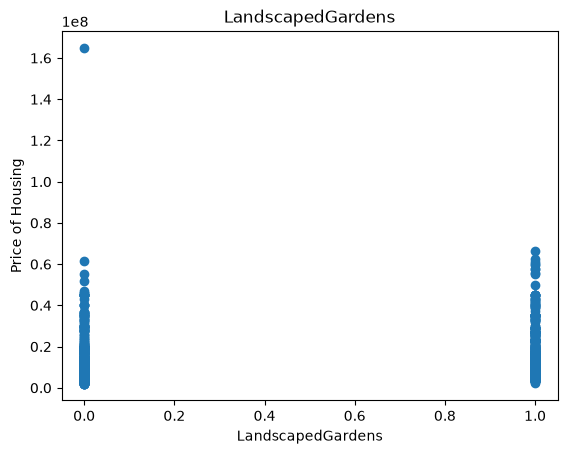

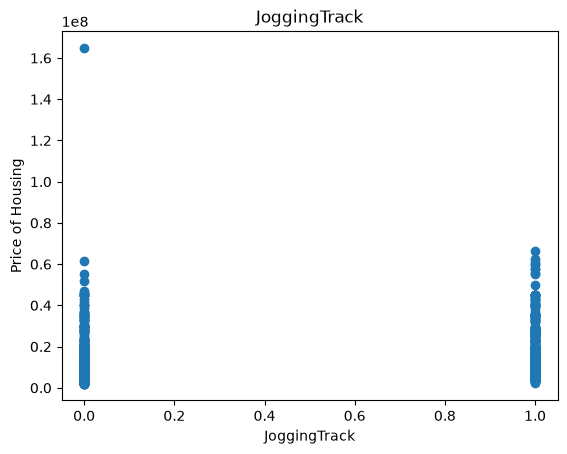

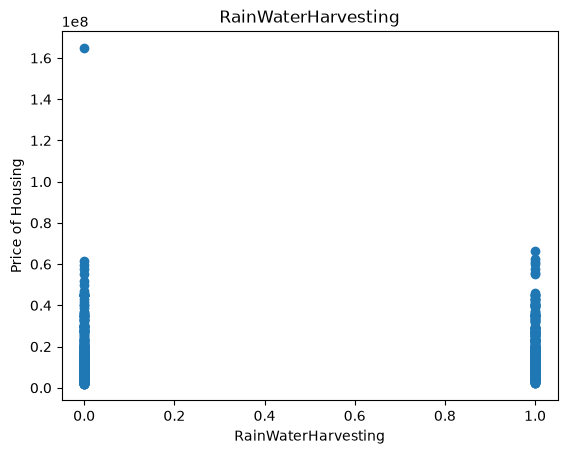

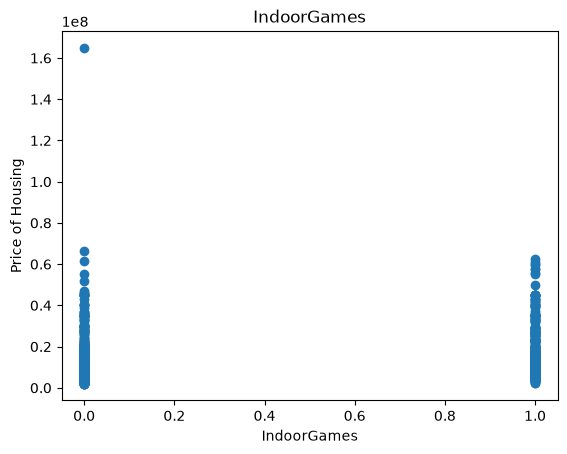

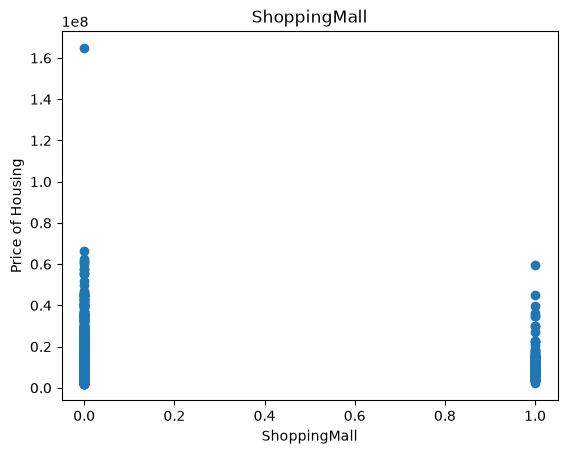

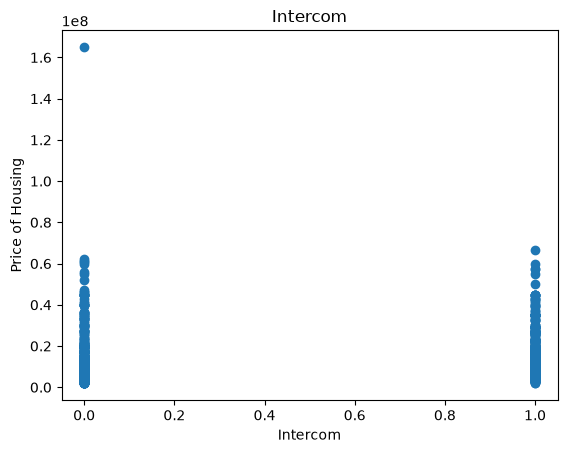

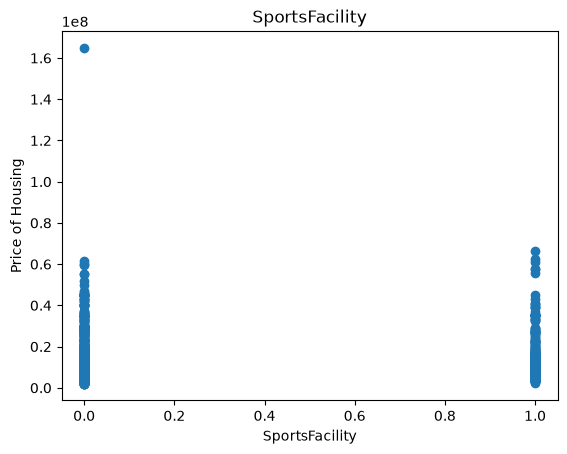

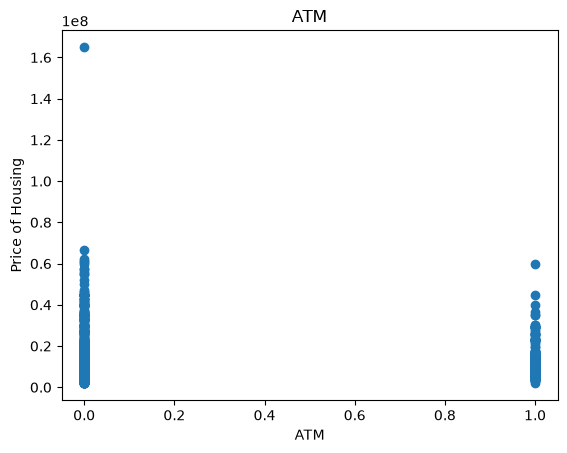

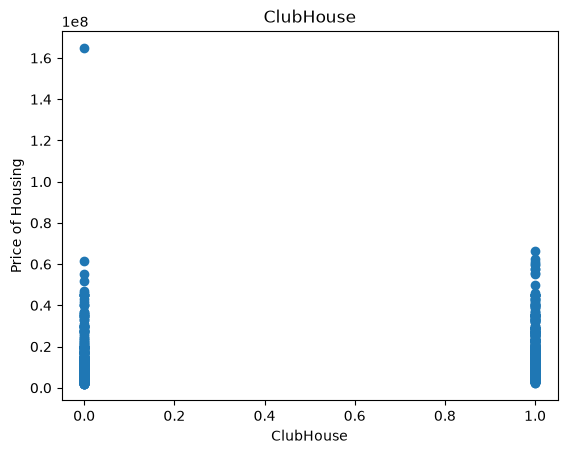

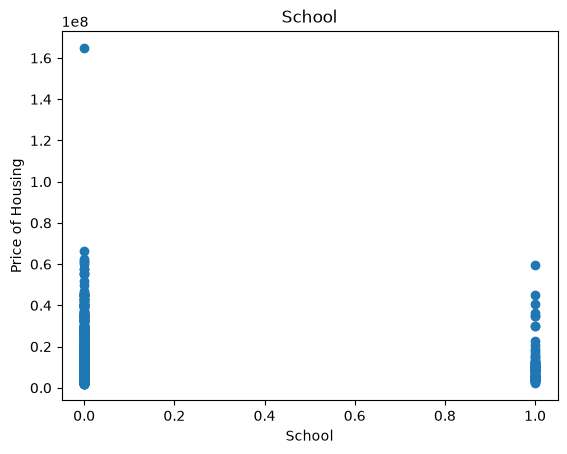

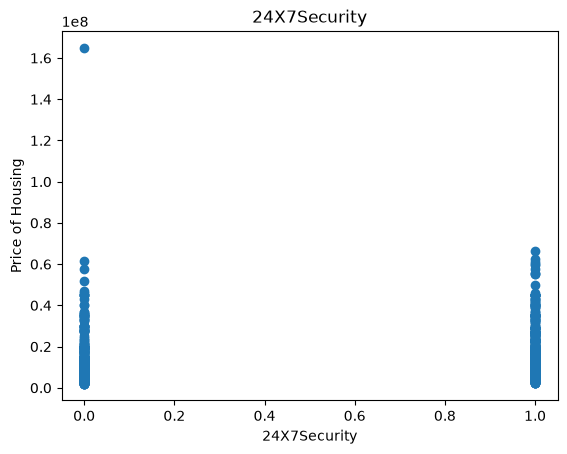

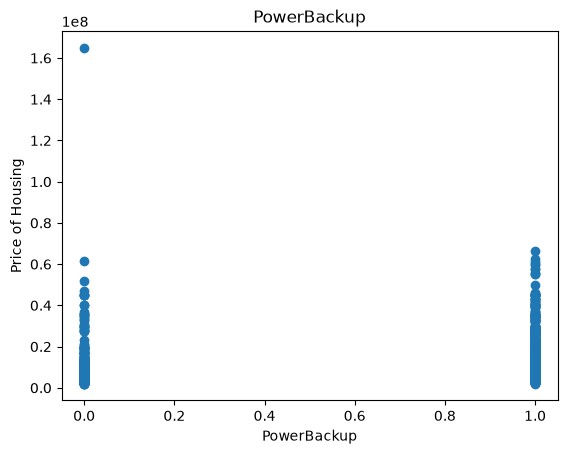

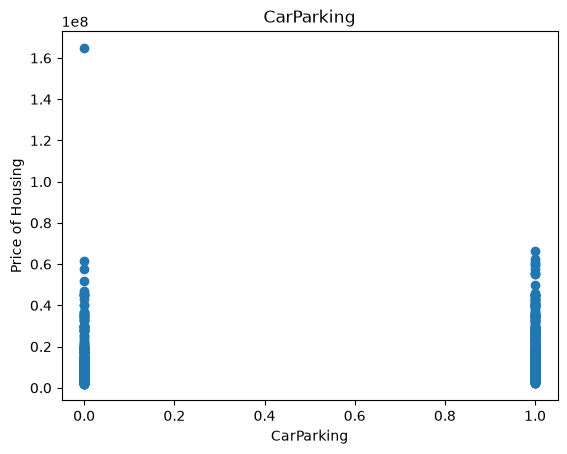

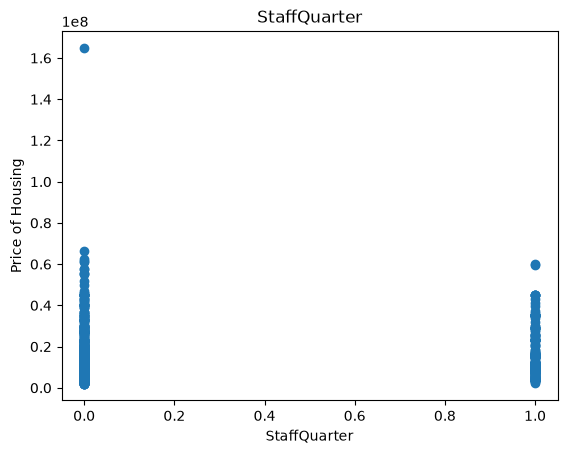

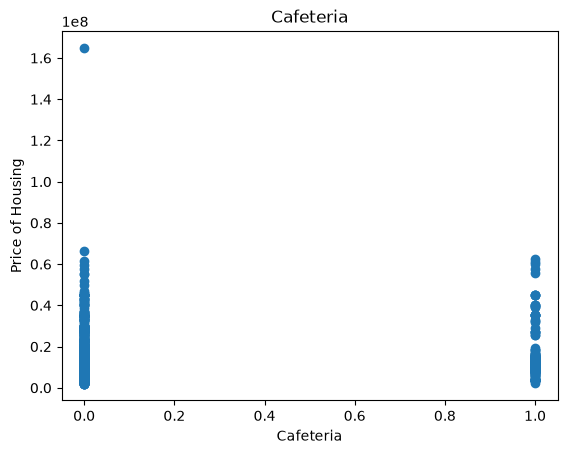

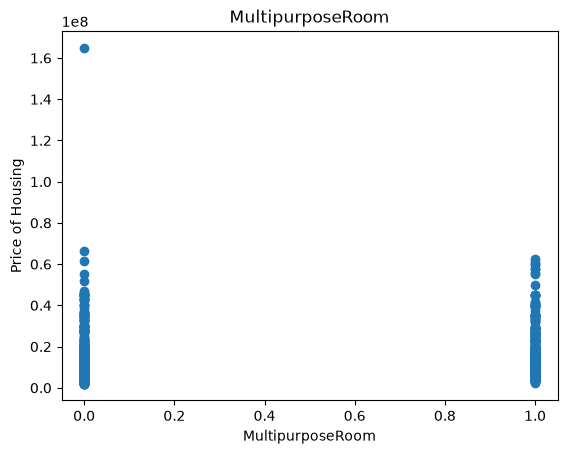

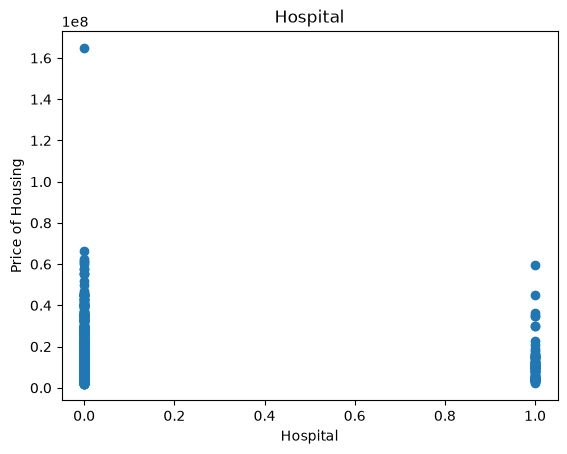

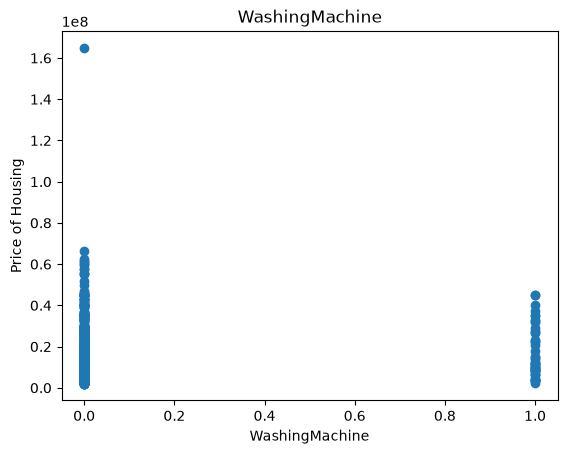

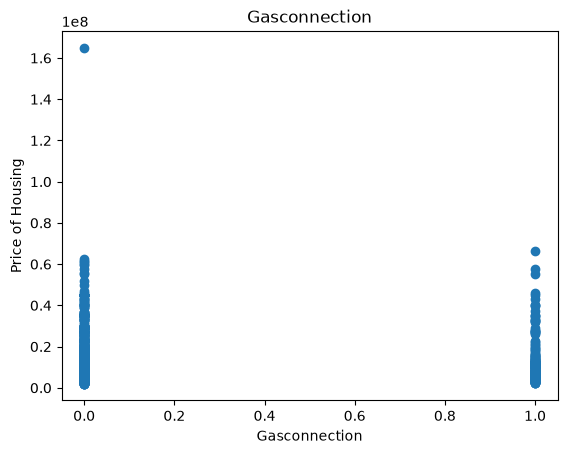

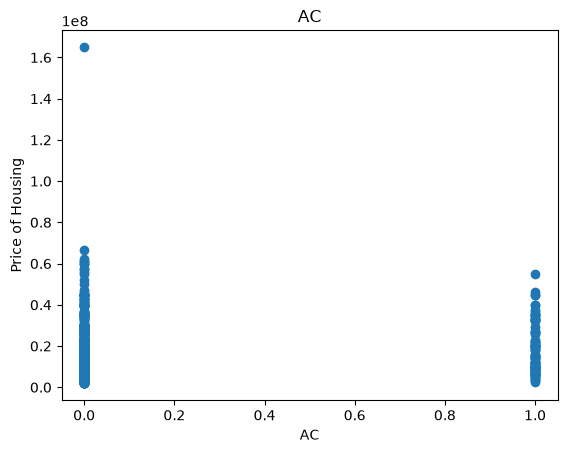

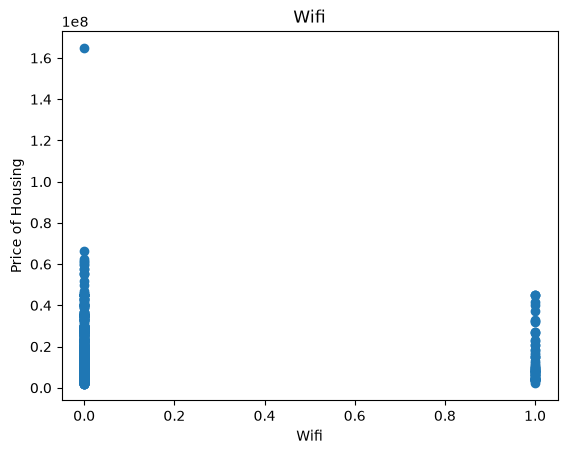

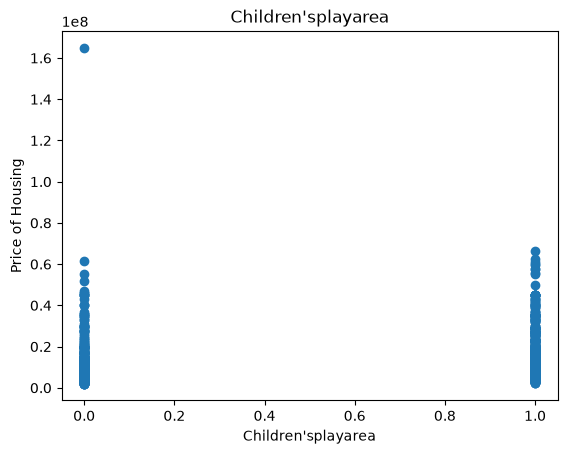

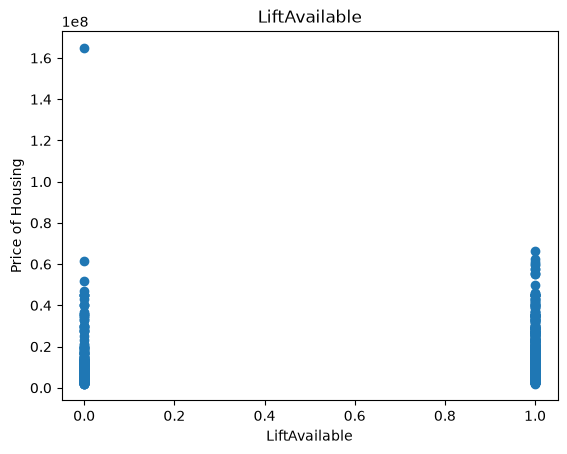

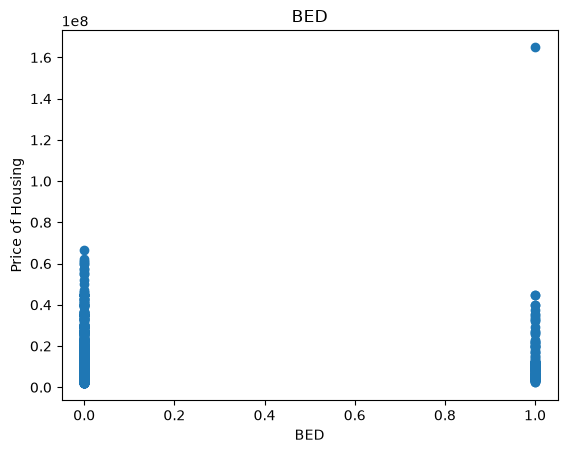

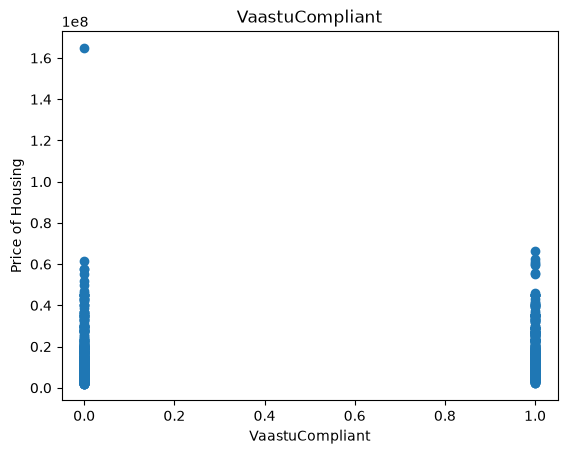

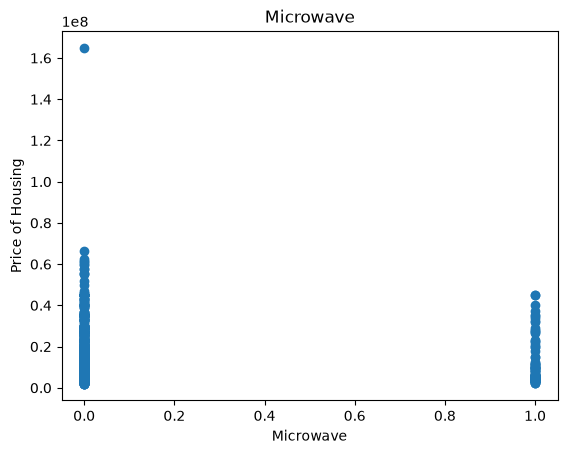

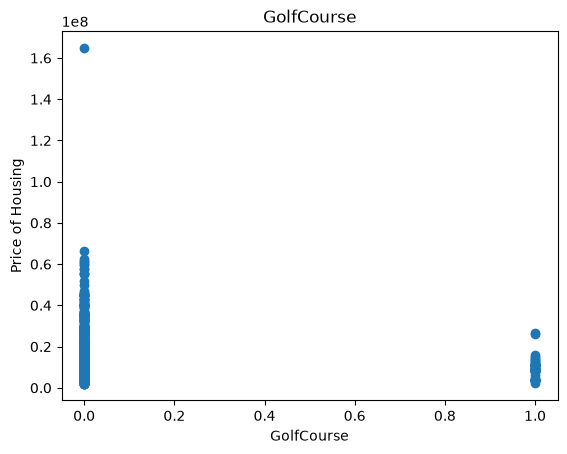

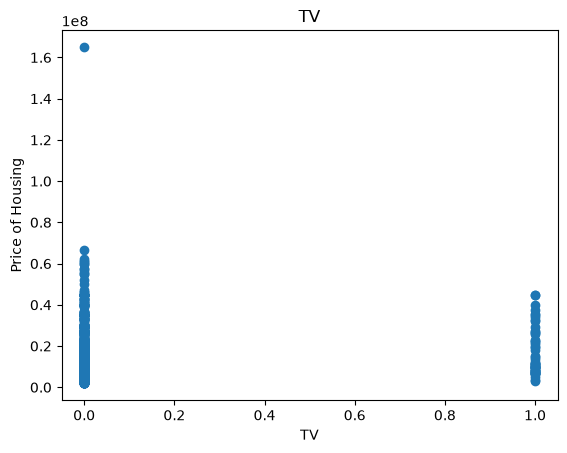

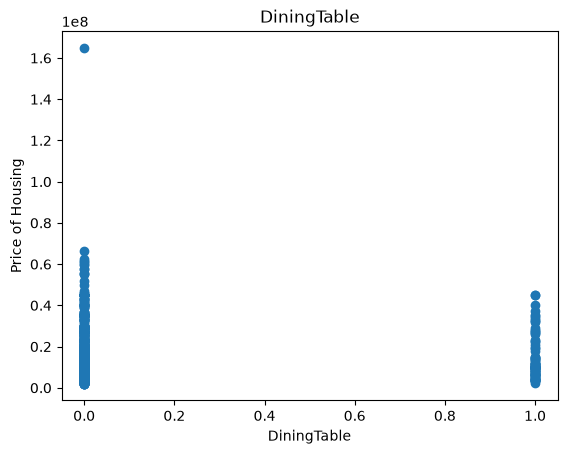

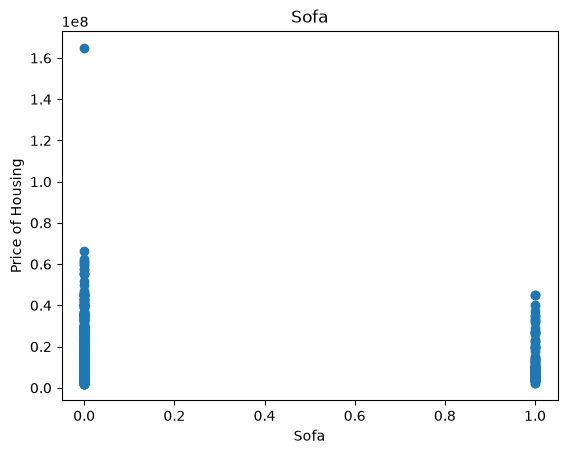

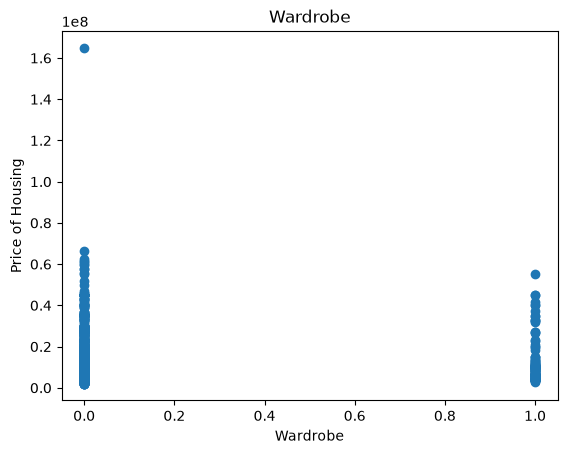

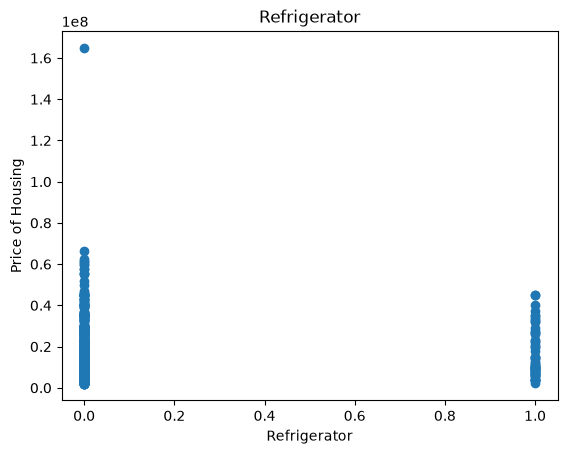

In [21]:
for label in df_clean.columns[1:]:
    plt.scatter(df_clean[label],df_clean['Price'])
    plt.title(label)
    plt.ylabel("Price of Housing")
    plt.xlabel(label)
    plt.show()

## Training and predicting 

The company allows you to use 3 different models for the housing price:

- Model 1: A multivariate linear regression using all features (benchmark)
- Model 2: Model 1 plus Lasso 
- Model 3: Model 1 plus Ridge

Use a 60/20/20 rule for the training/validation/testing set (set the state fixed). Models 2 - 3 contain **hyperparameters** which you need to tune. In general, do **NOT** use any cross-validation techniques. Instead do the following for Model 2 and 3: Make a vector of different values of the hyperparameter; then create a loop and estimate the ML models using the correct data. Make and show a plot of an appropriate loss function against the different values of the hyperparameter. 

**Important:** Make sure that your features are standardized!

## Deliverables
- Make Table 2 with parameter estimation results of Model 1. Report the constant, the first 5 coefficients (with their standard errors) and the R-squared. Interpret the coefficients related to *Area* and *MaintenanceStaff*. 
- An explanation, accompanied by tables or figures about the hyperparameters you will use for Model 2 and 3. 
- Table 3 with MAPE and MSPE of the predicted housing prices in the testing set.
- Take the best model and test whether the squared prediction errors are statistically different from the benchmark model (by the Diebold Mariano test). What is your conclusion?


# Model 1

In [ ]:
# Setting the X and Y variables 
# y = np.log(df_clean['Price'])
y = df_clean['Price']

X = df_clean.drop(columns=['Price']).astype(float)

In [ ]:
#Splitting the Training, Validation, and Testing Data 
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

#Print to validate 
print(len(X_train), len(X_val), len(X_test))

1429 477 477


In [86]:
#Applying the Scaler 
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

In [88]:
linreg = LinearRegression().fit(X_train_s, y_train)
linreg_val_mse = mean_squared_error(y_val, linreg.predict(X_val_s))
linreg_val_mae = mean_absolute_error(y_val, linreg.predict(X_val_s))
print("Multivariate Linear Regression validation MSE:", linreg_val_mse)
print("Multivariate Linear Regression validation MAE:", linreg_val_mae)
linreg.score(X_val_s, y_val)



Multivariate Linear Regression validation MSE: 52950997500205.75
Multivariate Linear Regression validation MAE: 2267466.4289852334


0.49567936562639225

In [45]:
def rmse(model, X_, y_):
    return np.sqrt(mean_squared_error(y_, model.predict(X_)))

# Lasso

In [91]:
lasso_alphas = np.logspace(-4, 0, 50)      # Lasso needs smaller alphas than Ridge
lasso_train_mse, lasso_val_mse = [], []

for a in lasso_alphas:
    m = Lasso(alpha=a, max_iter=10000)
    m.fit(X_train_s, y_train)
    lasso_train_mse.append(mean_squared_error(y_train, m.predict(X_train_s)))
    lasso_val_mse.append(mean_squared_error(y_val, m.predict(X_val_s)))

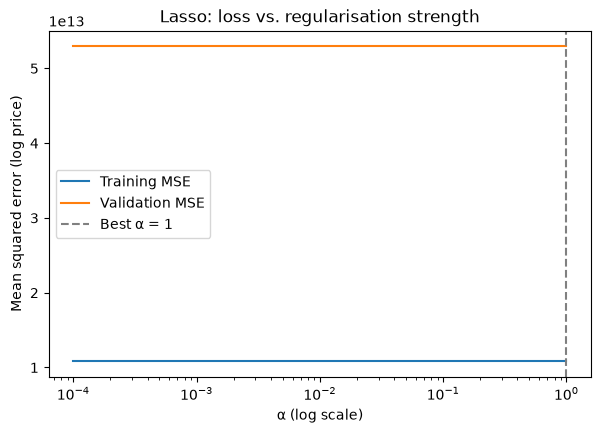

In [92]:
best_lasso_alpha = lasso_alphas[np.argmin(lasso_val_mse)]

plt.figure(figsize=(7, 4.5))
plt.plot(lasso_alphas, lasso_train_mse, label='Training MSE')
plt.plot(lasso_alphas, lasso_val_mse, label='Validation MSE')
plt.axvline(best_lasso_alpha, color='grey', linestyle='--', label=f'Best α = {best_lasso_alpha:.3g}')
plt.xscale('log')
plt.xlabel('α (log scale)')
plt.ylabel('Mean squared error (log price)')
plt.title('Lasso: loss vs. regularisation strength')
plt.legend()
plt.show()

# Ridge

In [93]:
ridge_alphas = np.logspace(-3, 3, 50)      # vector of hyperparameter values
ridge_train_mse, ridge_val_mse = [], []

for a in ridge_alphas:
    m = Ridge(alpha=a)
    m.fit(X_train_s, y_train)                                    # fit on training data
    ridge_train_mse.append(mean_squared_error(y_train, m.predict(X_train_s)))
    ridge_val_mse.append(mean_squared_error(y_val, m.predict(X_val_s)))   # judge on validation data

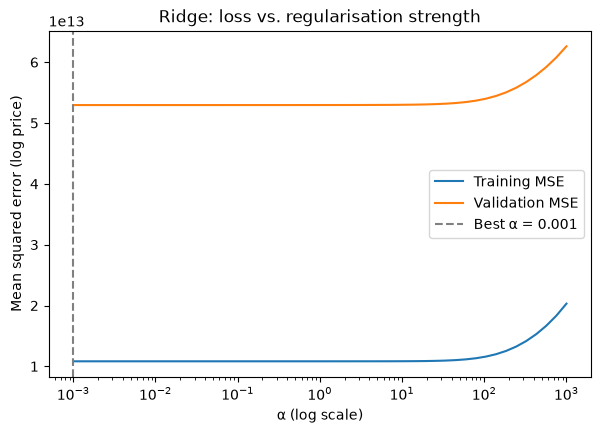

In [94]:
best_ridge_alpha = ridge_alphas[np.argmin(ridge_val_mse)]

plt.figure(figsize=(7, 4.5))
plt.plot(ridge_alphas, ridge_train_mse, label='Training MSE')
plt.plot(ridge_alphas, ridge_val_mse, label='Validation MSE')
plt.axvline(best_ridge_alpha, color='grey', linestyle='--', label=f'Best α = {best_ridge_alpha:.3g}')
plt.xscale('log')
plt.xlabel('α (log scale)')
plt.ylabel('Mean squared error (log price)')
plt.title('Ridge: loss vs. regularisation strength')
plt.legend()
plt.show()

In [95]:
ridge = Ridge(alpha=best_ridge_alpha).fit(X_train_s, y_train)
lasso = Lasso(alpha=best_lasso_alpha, max_iter=10000).fit(X_train_s, y_train)

lasso_coefs = pd.Series(lasso.coef_, index=X.columns)
print("Lasso kept", (lasso_coefs != 0).sum(), "of", len(lasso_coefs), "features")
print("Dropped:", list(lasso_coefs[lasso_coefs == 0].index))

Lasso kept 38 of 38 features
Dropped: []


In [101]:
for name, m in [('LinearRegression', linreg), ('Ridge', ridge), ('Lasso', lasso)]:
    test_mse = mean_squared_error(y_test, m.predict(X_test_s))
    test_mae = mean_absolute_error(y_test, m.predict(X_test_s))
    print(f"{name:6s} Test MAE: {test_mae:.4f} Test MSE: {test_mse:.4f}   Test RMSE: {np.sqrt(test_mse):.4f}")

LinearRegression Test MAE: 2314285.3173 Test MSE: 20489749863958.1641   Test RMSE: 4526560.4894
Ridge  Test MAE: 2314283.6695 Test MSE: 20489706584731.1680   Test RMSE: 4526555.7088
Lasso  Test MAE: 2314283.3197 Test MSE: 20489736901095.0977   Test RMSE: 4526559.0575


## Robustness Check

Test whether your results are robust with respect to the following two aspects

- Change the seed while creating your training/validation/testing set at least twice. What happens with your results?
- Given the original 60/20/20 rule, investigate the sensitiveness of rescaling your variables. That is what happens if you did NOT rescale the variables?

Regarding both aspects, create new tables (Table 4 an 5) with forecasting results (MSPE/MAPE) and associated Diebold Mariano tests results. 
Finally, provide a short recommendation which model you should use to model housing prices. **(max 60 words)**


In [102]:
#Splitting the Training, Validation, and Testing Data 
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=25)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=25)

#Print to validate 
print(len(X_train), len(X_val), len(X_test))

1429 477 477


In [103]:
for name, m in [('LinearRegression', linreg), ('Ridge', ridge), ('Lasso', lasso)]:
    test_mse = mean_squared_error(y_test, m.predict(X_test_s))
    test_mae = mean_absolute_error(y_test, m.predict(X_test_s))
    print(f"{name:6s} Test MAE: {test_mae:.4f} Test MSE: {test_mse:.4f}   Test RMSE: {np.sqrt(test_mse):.4f}")

LinearRegression Test MAE: 7988356.4969 Test MSE: 196011898475543.8438   Test RMSE: 14000424.9391
Ridge  Test MAE: 7988353.7643 Test MSE: 196011747858055.6875   Test RMSE: 14000419.5601
Lasso  Test MAE: 7988354.6047 Test MSE: 196011842091316.4688   Test RMSE: 14000422.9254
